--- DATASET SHAPE ---
(442, 12)

--- FIRST 5 ROWS ---
   id  age  sex   bmi     bp   s1     s2    s3   s4      s5  s6  target
0   1   59    2  32.1  101.0  157   93.2  38.0  4.0  4.8598  87     151
1   2   48    1  21.6   87.0  183  103.2  70.0  3.0  3.8918  69      75
2   3   72    2  30.5   93.0  156   93.6  41.0  4.0  4.6728  85     141
3   4   24    1  25.3   84.0  198  131.4  40.0  5.0  4.8903  89     206
4   5   50    1  23.0  101.0  192  125.4  52.0  4.0  4.2905  80     135

--- DATA INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      442 non-null    int64  
 1   age     442 non-null    int64  
 2   sex     442 non-null    int64  
 3   bmi     442 non-null    float64
 4   bp      442 non-null    float64
 5   s1      442 non-null    int64  
 6   s2      442 non-null    float64
 7   s3      442 non-null    float64
 8   s4      442 non

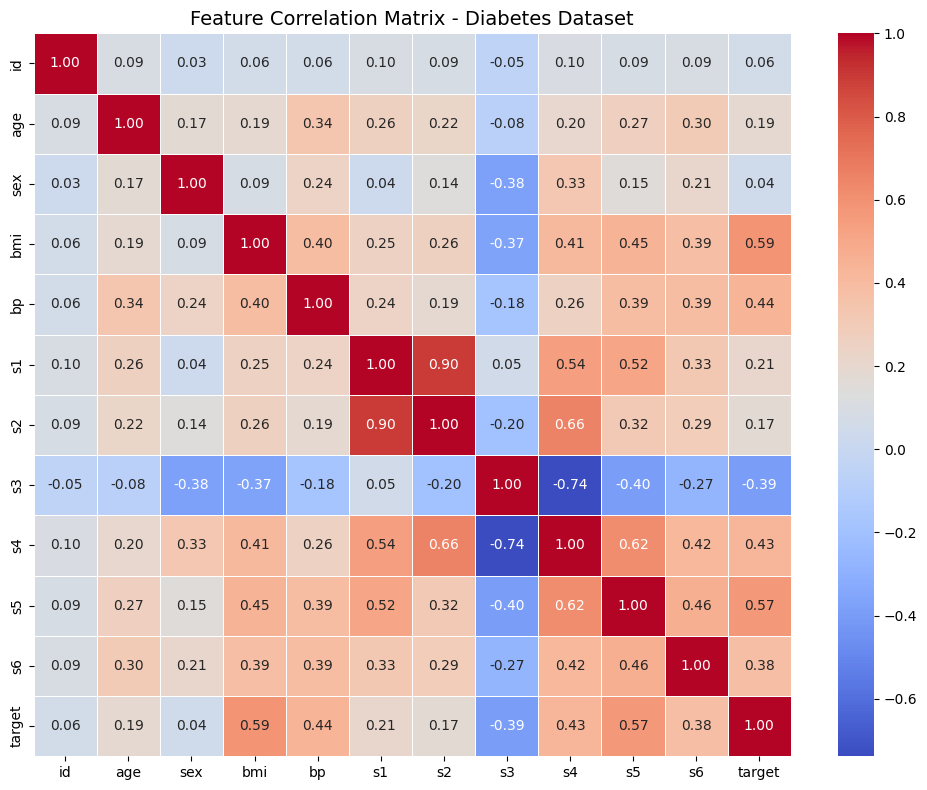


        LINEAR REGRESSION EVALUATION        
R-squared (R² Score) : 0.4526
Mean Squared Error (MSE) : 2900.1936
Root Mean Squared Error (RMSE): 53.8534
Mean Absolute Error (MAE): 42.7941

--- MODEL COEFFICIENTS ---
     age: 0.1377
     sex: -23.0645
     bmi: 5.8464
      bp: 1.1971
      s1: -1.2817
      s2: 0.8112
      s3: 0.6017
      s4: 10.1595
      s5: 67.1090
      s6: 0.2016
Intercept: -341.3782

--- MOST INFLUENTIAL FEATURES (RANKED) ---
Feature  Standardized_Coefficient  Absolute_Impact
     s1                -44.448856        44.448856
     s5                 35.161195        35.161195
    bmi                 25.607121        25.607121
     s2                 24.640954        24.640954
     bp                 16.828872        16.828872
     s4                 13.138784        13.138784
    sex                -11.511809        11.511809
     s3                  7.676978         7.676978
     s6                  2.351364         2.351364
    age                  1.753758 

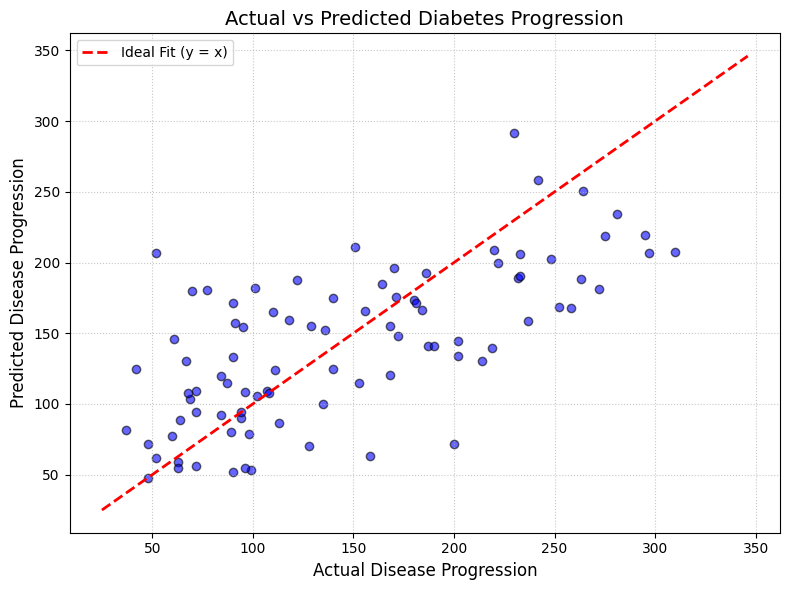

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import seaborn as sns

# Corrected the path to be a string enclosed in quotes
df = pd.read_csv("/content/scikit_learn_diabetes_raw.csv")

print("--- DATASET SHAPE ---")
print(df.shape)

print("\n--- FIRST 5 ROWS ---")
print(df.head())

print("\n--- DATA INFO ---")
df.info()

print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

print("\n--- SUMMARY STATISTICS ---")
print(df.describe())

# 2. Correlation Analysis & Heatmap
corr = df.corr()["target"].sort_values(ascending=False)
print("\n--- CORRELATION WITH TARGET ---")
print(corr)

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix - Diabetes Dataset", fontsize=14)
plt.tight_layout()
plt.savefig("feature_correlation_heatmap.png")
print("\n[INFO] Heatmap saved as 'feature_correlation_heatmap.png'")
plt.show()

# 3. Define Features (X) and Target (y)
X = df.drop(columns=["id", "target"], errors="ignore")
y = df["target"]

# 4. Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Train the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Predictions & Evaluation Metrics
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print("\n========================================")
print("        LINEAR REGRESSION EVALUATION        ")
print("========================================")
print(f"R-squared (R² Score) : {r2:.4f}")
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print("========================================")

print("\n--- MODEL COEFFICIENTS ---")
for col, coef in zip(X.columns, model.coef_):
  print(f"  {col:>6}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

# 7. Feature Importance Ranking (Using StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

importance_df = pd.DataFrame(
    {
        "Feature": X.columns,
        "Standardized_Coefficient": model_scaled.coef_,
        "Absolute_Impact": abs(model_scaled.coef_),
    }
).sort_values(by="Absolute_Impact", ascending=False)

print("\n--- MOST INFLUENTIAL FEATURES (RANKED) ---")
print(importance_df.to_string(index=False))

# 8. Actual vs Predicted Comparison Table (First 10 Samples)
comparison_df = pd.DataFrame(
    {
        "Actual Target": y_test.values[:10],
        "Predicted Value": np.round(y_pred[:10], 2),
        "Absolute Error": np.round(np.abs(y_test.values[:10] - y_pred[:10]), 2),
    }
)

print("\n--- ACTUAL VS PREDICTED VALUES (SAMPLE) ---")
print(comparison_df.to_string(index=False))

# 9. Actual vs Predicted Scatter Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6, edgecolors="k")
plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color="red",
    linestyle="--",
    lw=2,
    label="Ideal Fit (y = x)",
)
plt.xlabel("Actual Disease Progression", fontsize=12)
plt.ylabel("Predicted Disease Progression", fontsize=12)
plt.title("Actual vs Predicted Diabetes Progression", fontsize=14)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.savefig("actual_vs_predicted_plot.png")
print("\n[INFO] Scatter plot saved as 'actual_vs_predicted_plot.png'")
plt.show()